# Phase 7: Answering SQ2, SQ3 and SQ4

This notebook has three parts, one for each sub-question:

| Part | Question | Method | Figure |
|---|---|---|---|
| A | SQ2: What was the baseline between distance to the nearest station and car ownership per household in 2023, when accounting for income, urbanisation, household size, and density? | regression with control variables | coefficient plot |
| B | SQ3: How did the association between station distance and car ownership per household differ between major stations (intercity/junction hubs) and minor local stations in 2023? | regression per station type + interaction | two scatter plots |
| C | SQ4: Was the association between living near a station and car ownership per household weaker in neighbourhoods near stations with a high share of disrupted trains (2023)?  | regression with interaction | 3D surface (as in the lecture) |

## Step 1: Import the libraries and load the master dataset from Phase 5

In [1]:
# load pathlib, pandas, numpy, matplotlib, and statsmodels because we will use them to analyze the data
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# load the cleaned data
PROCESSED = Path('data/cleaned_data')
master = pd.read_pickle(PROCESSED / 'master.pkl')

## Step 2: Prepare the variables so the regression results are easier to read

- CBS codes urbanisation from 1 (very urban) to 5 (not urban). That is confusing to read, so we turn it around: `stedelijk` goes from 1 (not urban) to 5 (very urban).
- Density in thousands and disruptions in hundreds, so the coefficients are easier to read.
- `station_groot` from True/False to 1/0.

In [2]:
# Turn urbanisation around: 1= not urban, 5 = very urban
master['stedelijk'] = 6 - master['stedelijkheid']

# Rescale large numbers so the coefficients are easier to interpret
master['dichtheid_1000'] = master['dichtheid'] / 1000 # thousands of people per km2
master['storingen_100'] = master['storingen_per_jaar'] / 100 # hundreds of disruptions per year

#astype the station_groot variable to int so that it can be used in regression models
# True/False -> 1/0 (1 = major station) which means that the coefficient can be interpreted as the difference in number of disruptions between major and minor stations
master['station_groot'] = master['station_groot'].astype(int)

# The control variables we use in every mode so we can easily change them in one place if we want to add or remove controls
controles = 'inkomen + stedelijk + hh_grootte + dichtheid_1000'

Step 2b: Check for multicollinearity (feedback)


In [3]:
# OLS regression only works well if the explanatory variables are not too strongly related to each other.
# If two variables almost move together (for example urbanisation and density), the model cannot tell
# which of the two causes the effect. This is called multicollinearity.

# Step 1: correlation between every pair of variables (-1 to 1, close to 0 = not related)
variabelen = ['afstand_station', 'inkomen', 'stedelijk', 'hh_grootte', 'dichtheid_1000',
              'station_groot', 'pct_verstoord']
master[variabelen].corr().round(2)


,afstand_station,inkomen,stedelijk,hh_grootte,dichtheid_1000,station_groot,pct_verstoord
afstand_station,1.00,0.01,-0.51,0.30,-0.33,-0.09,-0.02
inkomen,0.01,1.00,-0.05,0.14,-0.06,0.06,0.00
stedelijk,-0.51,-0.05,1.00,-0.52,0.70,0.29,0.18
hh_grootte,0.30,0.14,-0.52,1.00,-0.41,-0.27,-0.13
dichtheid_1000,-0.33,-0.06,0.70,-0.41,1.00,0.22,0.14
station_groot,-0.09,0.06,0.29,-0.27,0.22,1.00,0.33
pct_verstoord,-0.02,0.00,0.18,-0.13,0.14,0.33,1.00


In [4]:
# Step 2: VIF (variance inflation factor) per variable.
# We explain one variable with all the other variables in a regression, and look at the R-squared.
# VIF = 1 / (1 - R-squared). If the other variables explain this variable well, the VIF is high.
# Rule of thumb: VIF below 5 is fine, between 5 and 10 is a warning, above 10 is a problem.
vif_waarden = []
for var in variabelen:
    andere = []                                                        # all variables except this one
    for v in variabelen:
        if v != var:
            andere.append(v)
    formule = var + ' ~ ' + ' + '.join(andere)                         # for example 'inkomen ~ afstand_station + stedelijk + ...'
    r2 = smf.ols(formule, data=master).fit().rsquared
    vif_waarden.append(1 / (1 - r2))

vif = pd.DataFrame({'variable': variabelen, 'VIF': vif_waarden}).round(2)
vif.sort_values('VIF', ascending=False)


,variable,VIF
2,stedelijk,2.72
4,dichtheid_1000,1.99
3,hh_grootte,1.44
0,afstand_station,1.37
5,station_groot,1.24
6,pct_verstoord,1.14
1,inkomen,1.03


---
# Step 3 SQ2: Is distance to the station related to car ownership?



In [5]:
# Run the regression model with the specified formula and control variables
# smf.ols is used to fit an ordinary least squares regression model
# The formula specifies that we are predicting 'autos_per_hh' (number of cars per household) based on 'afstand_station' (distance to the station) and the control variables defined in 'controles'.
# data=master specifies that we are using the 'master' DataFrame as the source of our data.
# The .fit() method fits the model to the data, and the results are stored in 'model_a'.
model_a = smf.ols('autos_per_hh ~ afstand_station + ' + controles, data=master).fit()
print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:           autos_per_hh   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     5635.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:40:04   Log-Likelihood:                 2704.7
No. Observations:                9039   AIC:                            -5397.
Df Residuals:                    9033   BIC:                            -5355.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.3306      0.017     

In [6]:
# Extract the coefficient for 'afstand_station' from the regression model results. This coefficient represents the estimated change in the number of cars per household for each additional kilometer away from a station.
b = model_a.params['afstand_station']

# Print the results of the regression analysis, including the coefficient for distance to the station, the estimated increase in cars per household for a 10 km increase in distance, and the R-squared value of the model, which indicates how well the model explains the variability in the data.
print(f'Each extra km to the station: {b:.4f} more cars per household')

# Calculate the estimated increase in the number of cars per household for a 10 km increase in distance from a station by multiplying the coefficient 'b' by 10. This provides a more tangible interpretation of the effect of distance on car ownership.
print(f'10 km further from a station:  {10 * b:.3f} more cars per household')

# Print the R-squared value of the regression model, which indicates the proportion of variance in the dependent variable (number of cars per household) that is predictable from the independent variables (distance to station and control variables). A higher R-squared value suggests a better fit of the model to the data.
print(f'R-squared: {model_a.rsquared:.2f}')

Each extra km to the station: 0.0050 more cars per household
10 km further from a station:  0.050 more cars per household
R-squared: 0.76



The variables have different units (km, euros, persons), so we cannot compare their coefficients directly. We therefore **standardise** all variables first: we subtract the mean and divide by the standard deviation. A coefficient then means: *if this variable goes up by one standard deviation, how many standard deviations does car ownership change?*

The dot is the estimate, the line is the 95% confidence interval. If the line does not cross 0, the effect is significant.

In [7]:
#standardise all variables (mean 0, standard deviation 1)

# column = variable to standardise
column = ['autos_per_hh', 'afstand_station', 'inkomen', 'stedelijk', 'hh_grootte', 'dichtheid']

# master[column] - master[column].mean() = subtract the mean of the variable from each value
# master[column].std() = divide by the standard deviation of the variable
standardized = (master[column] - master[column].mean()) / master[column].std()

# the same regression on the standardised data
# smf.ols is used to fit an ordinary least squares regression model
# data=standardized specifies that we are using the 'standardized' DataFrame as the source of our data.
model_std = smf.ols('autos_per_hh ~ afstand_station + inkomen + stedelijk + hh_grootte + dichtheid',
                    data=standardized).fit()

# Put estimates and confidence intervals in one table (without the intercept)

# model_std.params.drop('Intercept') contains the estimated coefficients for each variable in the regression model, including the intercept. 
# The .drop('Intercept') method removes the intercept from the results, leaving only the coefficients for the predictor variables.
coef = model_std.params.drop('Intercept')

# model_std.conf_int().drop('Intercept') contains the confidence intervals for each coefficient in the regression model, excluding the intercept.
ci = model_std.conf_int().drop('Intercept')

# Create a DataFrame to display the coefficients and their confidence intervals in a clear format
coef  

afstand_station    0.034122
inkomen            0.137442
stedelijk         -0.315976
hh_grootte         0.417924
dichtheid         -0.262199
dtype: float64

Plot the standardised coefficients with their confidence intervals

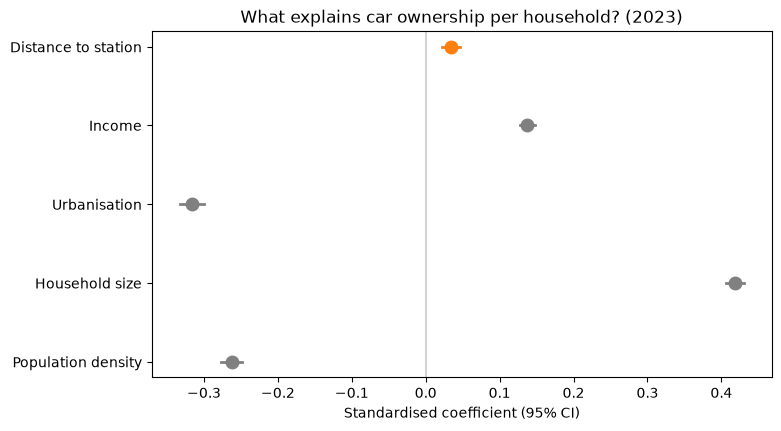

In [8]:
# create readible english names for the figure
names = {'afstand_station': 'Distance to station', 'inkomen': 'Income', 'stedelijk': 'Urbanisation',
         'hh_grootte': 'Household size', 'dichtheid': 'Population density'}

# create a figure to visualize the coefficients and their confidence intervals
fig, ax = plt.subplots(figsize=(8, 4.5))

# One horizontal line + dot per variable; distance is orange, the rest grey
# var in enumerate(namen) gives us the index (i) and the variable name (var) for each variable in the 'names' dictionary.
for i, var in enumerate(names):
    
    # kleur = 'tab:orange' if var == 'afstand_station' else 'grey' sets the color of the line and dot to orange for the distance variable and grey for all other variables.
    kleur = 'tab:orange' if var == 'afstand_station' else 'grey'
    # ci.loc[var, 0] and ci.loc[var, 1] access the lower and upper bounds of the confidence interval for the variable 'var' from the 'ci' DataFrame.
    # [i,i], color=kleur, linewidth=2) draws a horizontal line representing the confidence interval for the variable 'var' at the vertical position 'i' on the plot.
    ax.plot([ci.loc[var, 0], ci.loc[var, 1]], [i, i], color=kleur, linewidth=2)   
    # coef[var] accesses the estimated coefficient for the variable 'var' from the 'coef' Series.
    # 'o', color=kleur, markersize=9) plots a dot at the estimated coefficient value for the variable 'var' at the vertical position 'i' on the plot,
    ax.plot(coef[var], i, 'o', color=kleur, markersize=9)               

ax.axvline(0, color='lightgrey', zorder=0)    # vertical line at 0 = no effect
ax.set_yticks(range(len(names))) # set the y-ticks to correspond to the number of variables
ax.set_yticklabels(names.values()) # set the y-tick labels to the variable names
ax.invert_yaxis()   # first variable at the top
ax.set_xlabel('Standardised coefficient (95% CI)') # set the x-axis label to indicate that the coefficients are standardised and include 95% confidence intervals
ax.set_title('What explains car ownership per household? (2023)') # set the title of the plot to indicate that it shows factors explaining car ownership per household in 2023
plt.show() # display the plot



**Reading the figure:** Distance to the station has a positive and statistically significant association with car ownership, but its effect is relatively small compared to household size, urbanisation and population density. Neighbourhoods further from a station tend to have slightly higher car ownership, even after controlling for the other variables in the model.

---
# Step 4: SQ3 Is the relation different for major and minor stations?

### Figure: car ownership vs. distance, per station type

Each dot is a neighbourhood. The line is a simple regression line through the dots (without control variables). Since Phase 5 the data only contains neighbourhoods within 10 km of a station, so the x-axis runs from 0 to 10 km.

Plot car ownership against distance separately for major and minor stations 

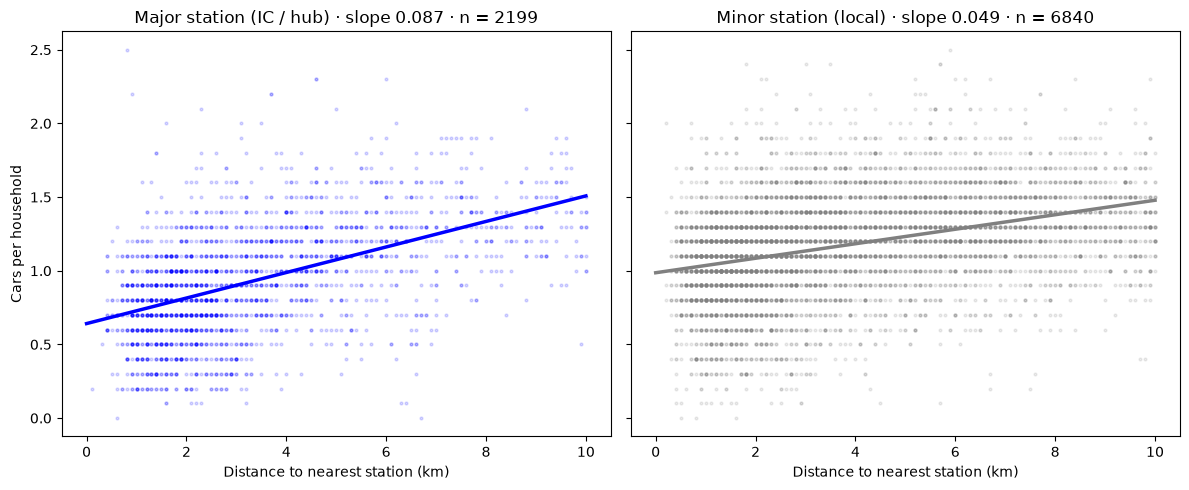

In [9]:
# Only neighbourhoods up to 10 km, for a readable figure
closeby = master[master['afstand_station'] <= 10]

# Define groups for the plot (title and colour)
groups = [(1, 'Major station (IC / hub)', 'blue'),
           (0, 'Minor station (local)', 'grey')]

# makes 2 plots next to each other
# sharey=True gives both panels the same y-axis, so the two groups are easy to compare
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# the zip function combines the axes and groups into pairs, allowing us to iterate over both simultaneously. For each pair, we extract the axis (ax) and the group information (is_major, title, color).
for ax, (is_major, title, color) in zip(axes, groups):
    # select the subset of the data corresponding to the current group (major or minor station) based on the 'station_groot' variable. 
    # This allows us to analyze and plot the data separately for each group.
    part = closeby[closeby['station_groot'] == is_major]

    # Simple regression line: slope and intercept with np.polyfit
    # np.polyfit is a function from the NumPy library that fits a polynomial of a specified degree to a set of data points. 
    # In this case, we are fitting a linear polynomial (degree 1) to the data points defined by the 'afstand_station' (distance to station) and 'autos_per_hh' (number of cars per household) columns in the 'part' DataFrame.
    slope, intercept = np.polyfit(part['afstand_station'], part['autos_per_hh'], 1)
    
    # s=4 means that the size of the scatter plot points will be 4, and alpha=0.15 makes the points semi-transparent to reduce visual clutter when many points overlap.
    ax.scatter(part['afstand_station'], part['autos_per_hh'], s=4, alpha=0.15, color=color)

     # Draw the regression line from 0 to 10 km: at 0 km its height is the intercept,
    # at 10 km it is the intercept plus 10 times the slope
    # np.array is needed: a normal list cannot be multiplied by a number
    x_line = np.array([0, 10])
    ax.plot(x_line, intercept + slope * x_line, color=color, linewidth=2.5)

    ax.set_title(f'{title} · slope {slope:.3f} · n = {len(part)}')
    ax.set_xlabel('Distance to nearest station (km)')

axes[0].set_ylabel('Cars per household')
plt.tight_layout()
plt.show()

The slopes above do not take the control variables into account. To test whether the difference is real, we estimate one model with an **interaction** `afstand_station * station_groot` and the control variables.

In [10]:
# smf.ols is used to fit an ordinary least squares regression model with an interaction term 
# afstand_station * station_groot means that we are including an interaction term between distance to the station and whether the station is major or minor. This allows us to see if the effect of distance on car ownership differs between major and minor stations.
# data =master specifies that we are using the 'master' DataFrame as the source of our data.
# .fit() fits the model to the data, and the results are stored in 'model_b'.
model_b = smf.ols('autos_per_hh ~ afstand_station * station_groot + ' + controles, data=master).fit()
print(model_b.summary())

                            OLS Regression Results                            
Dep. Variable:           autos_per_hh   R-squared:                       0.758
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     4051.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:40:05   Log-Likelihood:                 2727.0
No. Observations:                9039   AIC:                            -5438.
Df Residuals:                    9031   BIC:                            -5381.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

Calculate the slope of distance for minor and for major stations and test the difference

In [11]:
# Extract the coefficients for the distance to station variable and the interaction term from the regression model results.
slope_small = model_b.params['afstand_station']

# The slope for major stations is calculated by adding the coefficient of the interaction term (afstand_station:station_groot) to the slope for minor stations. This gives us the estimated change in the number of cars per household for each additional kilometer away from a major station.
slope_large = slope_small + model_b.params['afstand_station:station_groot']

# The p-value for the difference in slopes between minor and major stations is extracted from the regression model results.
p_difference = model_b.pvalues['afstand_station:station_groot']

# Print the results of the regression analysis, including the slopes for minor and major stations, the p-value for the difference in slopes, and the difference in level near a major station. The slopes indicate how car ownership changes with distance from the station, while the p-value indicates whether the difference in slopes is statistically significant. The difference in level shows how many more cars per household are associated with being near a major station compared to a minor station.
print(f'Slope near minor stations (with controls): {slope_small:.4f} cars per km')
print(f'Slope near major stations (with controls): {slope_large:.4f} cars per km')
print(f'p-value of the difference: {p_difference:.3f}')
print(f'Difference in level near a major station: {model_b.params["station_groot"]:.3f} cars per household')

Slope near minor stations (with controls): 0.0055 cars per km
Slope near major stations (with controls): 0.0052 cars per km
p-value of the difference: 0.856
Difference in level near a major station: -0.030 cars per household


**Reading the result:** in the raw data, the line is steeper near major stations. After adding the control variables, both slopes become much smaller and the difference between them is not significant (p > 0.05). Neighbourhoods near a major station do have slightly lower car ownership overall.

---
# Step 5: SQ4 Is the relation weaker near stations with many disruptions?

We add an interaction between distance and the share of disrupted trains at the nearest station (`pct_verstoord`, cancelled or 5+ minutes late in 2023). We use a share instead of the number of disruptions (feedback), because big stations have more disruptions simply because more trains stop there. We keep `station_groot` in the model as a control.

First estimate a regression with an interaction between distance and the share of disrupted trains

In [12]:
# smf.ols is used to fit an ordinary least squares regression model with an interaction term 
# afstand_station * pct_verstoord means that we are including an interaction term between distance to the station and the share (%) of disrupted trains at that station. This allows us to see if the effect of distance on car ownership differs between reliable and less reliable stations.
# data =master specifies that we are using the 'master' DataFrame as the source of our data.
# .fit() fits the model to the data, and the results are stored in 'model_c'.
model_c = smf.ols('autos_per_hh ~ afstand_station * pct_verstoord + station_groot + ' + controles, data=master).fit()

# Print the summary of the regression model 'model_c', which includes the estimated coefficients, standard errors, t-values, p-values, and other statistics that help assess the fit and significance of the model. This summary provides insights into how distance to the station and the number of disruptions interact to affect car ownership per household, while controlling for other variables.
print(model_c.summary())

                            OLS Regression Results                            
Dep. Variable:           autos_per_hh   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     3545.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:40:05   Log-Likelihood:                 2728.2
No. Observations:                9025   AIC:                            -5438.
Df Residuals:                    9016   BIC:                            -5374.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

 Calculate how the slope of distance changes at a low, average and high share of disrupted trains

In [13]:
# Extract the coefficient for the interaction term 'afstand_station:pct_verstoord' from the regression model results.
print(f"Interaction distance x share of disrupted trains: {model_c.params['afstand_station:pct_verstoord']:.4f}")

# The p-value for the interaction term is extracted from the regression model results to assess the statistical significance of the interaction effect between distance to the station and the share of disrupted trains on car ownership per household.
print(f"p-value: {model_c.pvalues['afstand_station:pct_verstoord']:.3f}")

# The slope of distance is calculated at a low (25%), average (50%) and high (75%) share of disrupted trains.
# quantile gives the value below which 25%, 50% or 75% of the neighbourhoods are
for deel in [0.25, 0.50, 0.75]:
    pct = master['pct_verstoord'].quantile(deel)

    # The slope is the coefficient for 'afstand_station' plus the interaction coefficient times the share of disrupted trains.
    # This gives the change in cars per household for each extra km from the station, at this level of disruptions.
    slope = model_c.params['afstand_station'] + model_c.params['afstand_station:pct_verstoord'] * pct

    print(f'Slope of distance at {pct:.1f}% disrupted trains: {slope:.4f} cars per km')


Interaction distance x share of disrupted trains: 0.0001
p-value: 0.539
Slope of distance at 7.9% disrupted trains: 0.0050 cars per km
Slope of distance at 10.7% disrupted trains: 0.0053 cars per km
Slope of distance at 13.4% disrupted trains: 0.0056 cars per km



x = distance, y = share of disrupted trains (%), height = predicted car ownership (minor station, control variables at their average).

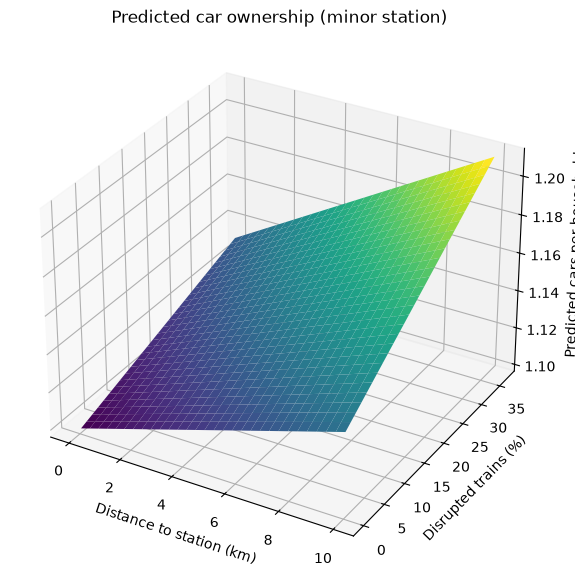

In [14]:
# grid of distances and disruptions (np.meshgrid, as in the lecture)
x = np.linspace(0, 10, 30)     # distance in km (only up to 10 km, see Phase 5)
y = np.linspace(master['pct_verstoord'].min(), master['pct_verstoord'].max(), 30)      # share of disrupted trains in %
x, y = np.meshgrid(x, y)        # np.meshgrid creates a rectangular grid out of two given one-dimensional arrays representing the Cartesian indexing or Matrix indexing. In this case, it creates a grid of distances (x) and disruptions (y) for plotting the predicted car ownership across different combinations of these two variables.

# a table with every grid point, controls at their average, minor station
average = master[['inkomen', 'stedelijk', 'hh_grootte', 'dichtheid_1000']].mean()

# Create a DataFrame called 'raster' that contains the flattened grid of distances (x) and disruptions (y), along with a column for 'station_groot' set to 0 (indicating minor stations). This DataFrame will be used to predict car ownership across the grid of distances and disruptions while keeping control variables at their average values.
raster = pd.DataFrame({'afstand_station': x.flatten(), 'pct_verstoord': y.flatten(), 'station_groot': 0})

# Fill the raster DataFrame with the average values for each control variable
for column in average.index:

    # raster[column] = average[column] assigns the average value of the control variable 'column
    raster[column] = average[column]

#  predict and put back in grid shape
z = model_c.predict(raster).to_numpy().reshape(x.shape)

#  plot
fig = plt.figure(figsize=(9, 7)) # create a new figure with a specified size of 9 inches by 7 inches for the 3D surface plot
ax = fig.add_subplot(projection='3d') # add a 3D subplot to the figure, allowing us to create a three-dimensional surface plot of the predicted car ownership based on distance to the station and number of disruptions.
ax.plot_surface(x, y, z, cmap='viridis') # plot the 3D surface

ax.set_xlabel('Distance to station (km)')
ax.set_ylabel('Disrupted trains (%)')
ax.set_zlabel('Predicted cars per household')
ax.set_title('Predicted car ownership (minor station)')
plt.show()

**TO UPDATE after running with `pct_verstoord`. Old text (number of disruptions):** the interaction is positive: the effect of distance is *stronger* near stations with many disruptions, not weaker as we expected. A likely explanation is that the stations with the most disruptions are also the busiest stations with the most trains, so the number of disruptions partly measures how much rail service a station offers, not only how unreliable it is.